# Phase 1: Data Loading & Exploratory Data Analysis (EDA)
In this section, we load the data and perform integrity checks (duplicates, missing values, and data consistency).

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
import category_encoders as ce

train_df = pd.read_csv('train-test.csv')

print("--- Data Integrity & EDA Checks ---")
print(f"Total rows: {len(train_df)}")
print(f"Duplicate load_ids: {train_df.duplicated(subset=['load_id']).sum()}")
print(f"Fully duplicate rows: {train_df.duplicated().sum()}")
print("\nEquipment Categories:")
print(train_df['equipment'].value_counts())
print("\nMissing values per column:")
print(train_df.isnull().sum()[train_df.isnull().sum() > 0])
print("-----------------------------------\n")

Matplotlib is building the font cache; this may take a moment.


--- Data Integrity & EDA Checks ---
Total rows: 48000
Duplicate load_ids: 0
Fully duplicate rows: 0

Equipment Categories:
equipment
Dry Van    27202
Reefer     12045
Flatbed     8753
Name: count, dtype: int64

Missing values per column:
weight          300
market_index    374
dtype: int64
-----------------------------------



# Phase 2: Preprocessing & Feature Engineering
Handling data traps (e.g., negative weights) and extracting time-based features from the date column to capture seasonality.

In [4]:
def preprocess_data(df):
    data = df.copy()
    
    # 1. Fix negative weights (Data Trap)
    if 'weight' in data.columns:
        data['weight'] = data['weight'].abs()
        
    # 2. Extract Time Features
    if 'date' in data.columns:
        data['date'] = pd.to_datetime(data['date'])
        data['month'] = data['date'].dt.month
        data['day_of_week'] = data['date'].dt.dayofweek
        data['day_of_year'] = data['date'].dt.dayofyear
    
    return data

# Apply preprocessing
train_cleaned = preprocess_data(train_df)

# Define Target
target = 'posted_rate'

# Drop target and identifiers for training
X = train_cleaned.drop(columns=[target, 'load_id', 'date'])
y = np.log1p(train_cleaned[target]) # Log Transform to handle extreme freight rates

# Define feature groups for the pipeline
numeric_features = ['distance', 'weight', 'market_index', 'quote_signal', 
                    'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon',
                    'month', 'day_of_week', 'day_of_year']
categorical_features = ['equipment']
target_enc_features = ['pickup', 'delivery']

# Phase 2.5: Data Visualization & Insights
Before training, let's visualize the data to understand the relationships and why we applied the Log Transformation to the target variable.

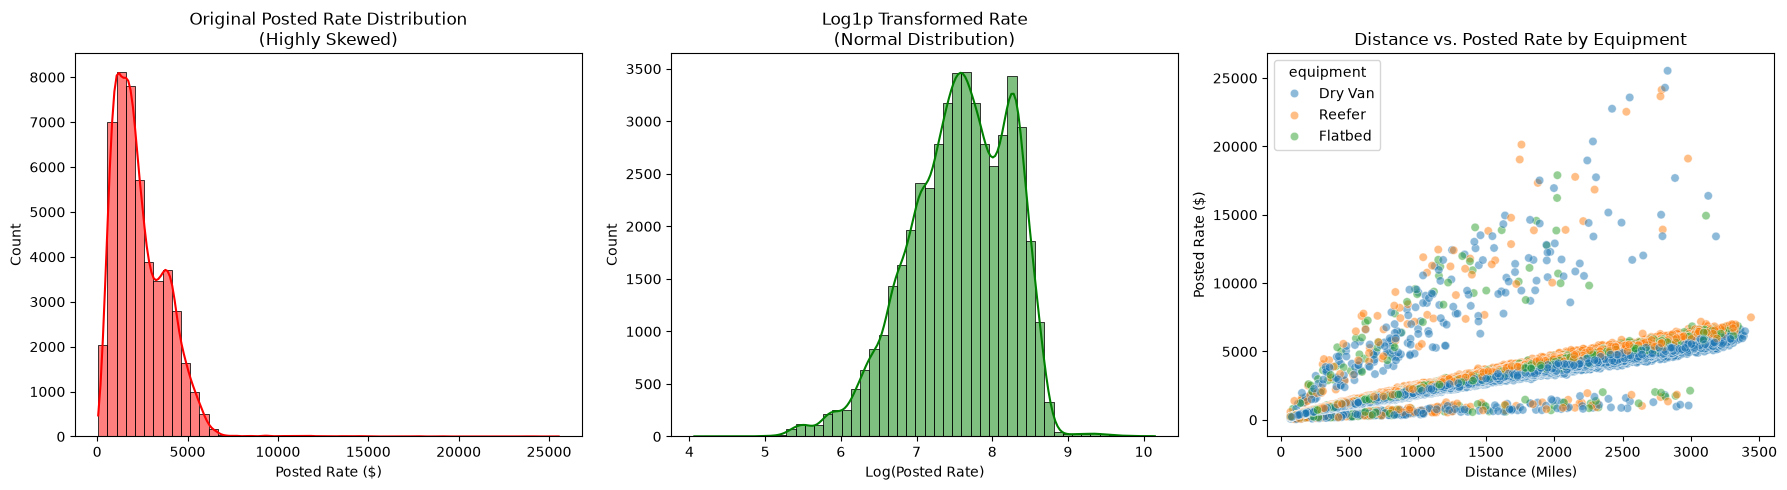

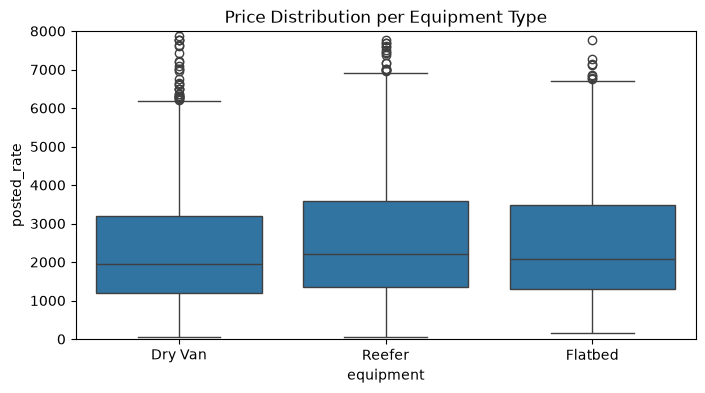

In [ ]:
import seaborn as sns

plt.figure(figsize=(18, 5))

plt.subplot(1, 3, 1)
sns.histplot(train_cleaned['posted_rate'], bins=50, kde=True, color='red')
plt.title('Original Posted Rate Distribution\n(Highly Skewed)')
plt.xlabel('Posted Rate ($)')

plt.subplot(1, 3, 2)
sns.histplot(np.log1p(train_cleaned['posted_rate']), bins=50, kde=True, color='green')
plt.title('Log1p Transformed Rate\n(Normal Distribution)')
plt.xlabel('Log(Posted Rate)')

plt.subplot(1, 3, 3)
sns.scatterplot(data=train_cleaned, x='distance', y='posted_rate', hue='equipment', alpha=0.5)
plt.title('Distance vs. Posted Rate by Equipment')
plt.xlabel('Distance (Miles)')
plt.ylabel('Posted Rate ($)')

plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
sns.boxplot(data=train_cleaned, x='equipment', y='posted_rate')
plt.title('Price Distribution per Equipment Type')
plt.ylim(0, 8000) 
plt.show()

# Phase 3: Model Pipelines, Training & Evaluation
Building end-to-end scikit-learn pipelines utilizing Target Encoding for high-cardinality cities. 
In this phase, we will train and compare two robust models (Random Forest and XGBoost) to automatically select the best performer based on the lowest Mean Absolute Error (MAE).

In [ ]:
from sklearn.ensemble import RandomForestRegressor

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

target_transformer = Pipeline(steps=[
    ('encoder', ce.TargetEncoder()) 
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features),
        ('target_enc', target_transformer, target_enc_features)
    ])

xgb_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=6, random_state=42, n_jobs=-1))
])

rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1))
])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training Random Forest...")
rf_model.fit(X_train, y_train)

print("Training XGBoost...")
xgb_model.fit(X_train, y_train)


rf_preds = np.expm1(rf_model.predict(X_test))
xgb_preds = np.expm1(xgb_model.predict(X_test))
y_test_real = np.expm1(y_test)

print("\n=== Model Comparison Results ===")
print(f"Random Forest -> RMSE: {np.sqrt(mean_squared_error(y_test_real, rf_preds)):.2f} | MAE: {mean_absolute_error(y_test_real, rf_preds):.2f}")
print(f"XGBoost       -> RMSE: {np.sqrt(mean_squared_error(y_test_real, xgb_preds)):.2f} | MAE: {mean_absolute_error(y_test_real, xgb_preds):.2f}")


best_model = xgb_model if mean_absolute_error(y_test_real, xgb_preds) < mean_absolute_error(y_test_real, rf_preds) else rf_model
print(f"\nThe Best Model selected for final predictions is: {best_model.steps[-1][1].__class__.__name__}")

model = best_model

Training Random Forest...
Training XGBoost...

=== Model Comparison Results ===
Random Forest -> RMSE: 547.01 | MAE: 118.39
XGBoost       -> RMSE: 533.76 | MAE: 101.54

🏆 The Best Model selected for final predictions is: XGBRegressor


# Phase 4: Final Predictions for Submission
Predicting the validation loads and the December scenario to generate the final submission files.

In [ ]:

# 1. Load evaluation files
val_df = pd.read_csv('validation.csv')
dec_df = pd.read_csv('december-chart-inputs.csv')
val_template = pd.read_csv('validation-predictions-template.csv')

# 2. Apply the exact same preprocessing
val_cleaned = preprocess_data(val_df)
dec_cleaned = preprocess_data(dec_df)

# 3. Drop identifiers to match training features
X_val = val_cleaned.drop(columns=['load_id', 'date'])
X_dec = dec_cleaned.drop(columns=['date', 'predicted_rate'], errors='ignore')

# THE FIX: Injecting missing columns for the December Scenario 

X_dec['market_index'] = train_df['market_index'].median()
X_dec['quote_signal'] = train_df['quote_signal'].median()

lex_lat = train_df[train_df['pickup'] == 'Lexington']['pickup_lat'].median()
lex_lon = train_df[train_df['pickup'] == 'Lexington']['pickup_lon'].median()
fw_lat = train_df[train_df['delivery'] == 'Fort Wayne']['delivery_lat'].median()
fw_lon = train_df[train_df['delivery'] == 'Fort Wayne']['delivery_lon'].median()

X_dec['pickup_lat'] = lex_lat
X_dec['pickup_lon'] = lex_lon
X_dec['delivery_lat'] = fw_lat
X_dec['delivery_lon'] = fw_lon

X_dec = X_dec[X_train.columns]

# 4. Generate Predictions
print("Generating Validation Predictions...")
val_preds_log = model.predict(X_val)
val_preds = np.expm1(val_preds_log)

print("Generating December Predictions...")
dec_preds_log = model.predict(X_dec)
dec_preds = np.expm1(dec_preds_log)

# 5. Save validation_predictions.csv
val_template['predicted_rate'] = val_preds
val_template.to_csv('validation_predictions.csv', index=False)
print("Saved: validation_predictions.csv")

# 6. Save December predictions (keeping original columns as required by score.py)
dec_df['predicted_rate'] = dec_preds
dec_df.to_csv('completed_december.csv', index=False)
print("Saved: completed_december.csv")

print("\n Pipeline executed successfully! You are now ready to run score.py in the terminal.")

Generating Validation Predictions...
Generating December Predictions...
Saved: validation_predictions.csv
Saved: completed_december.csv

🎉 Pipeline executed successfully! You are now ready to run score.py in the terminal.


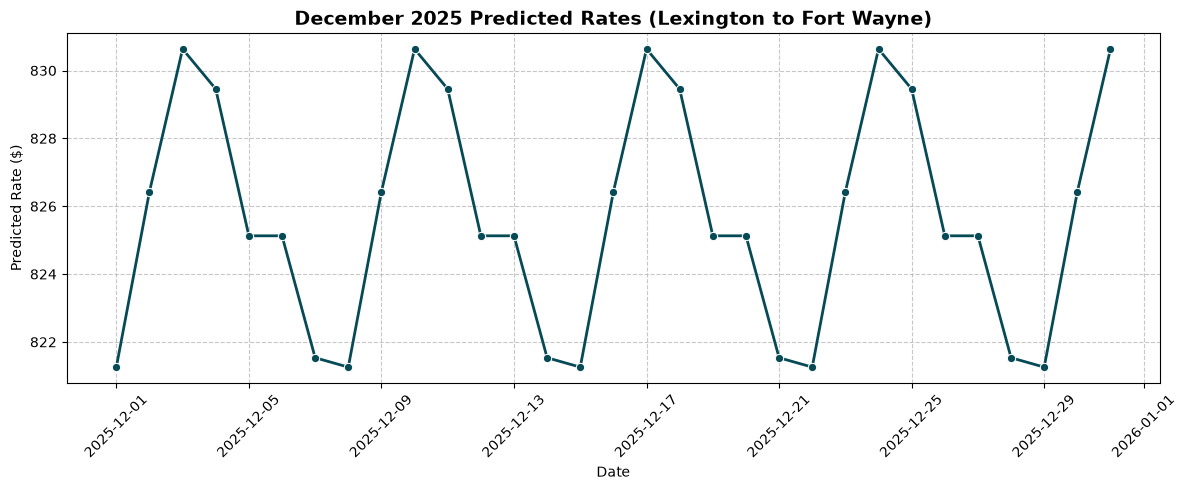

        date  predicted_rate
0 2025-12-01       821.25760
1 2025-12-02       826.42694
2 2025-12-03       830.63367
3 2025-12-04       829.45470
4 2025-12-05       825.12790

Lowest Expected Rate: $821.26
Highest Expected Rate: $830.63


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

dec_results = pd.read_csv('completed_december.csv')
dec_results['date'] = pd.to_datetime(dec_results['date'])

plt.figure(figsize=(12, 5))
sns.lineplot(data=dec_results, x='date', y='predicted_rate', marker='o', color='#064A56', linewidth=2)

plt.title('December 2025 Predicted Rates (Lexington to Fort Wayne)', fontsize=14, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Predicted Rate ($)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(dec_results[['date', 'predicted_rate']].head())
print(f"\nLowest Expected Rate: ${dec_results['predicted_rate'].min():.2f}")
print(f"Highest Expected Rate: ${dec_results['predicted_rate'].max():.2f}")